# Q11. Which brain area contains most information about variable A?

*Exclude inter-trial intervals. The trial segment is not given, because it cannot be determined a priori for variable A.*

**Approach: decoding.** How well can variable A be predicted, trial by trial, from the spikes of each area?
- **Decoder:** logistic regression with 5-fold cross-validation, scored by **ROC AUC**. 0.5 is chance and 1 is perfect. AUC is unaffected by A being unbalanced (~80% of trials have A = 1).
- **Same number of units per area:** larger populations decode better simply because they have more units. So every decoder uses **5 units** (the smallest area has 5), drawn at random 20 times. Full populations are a check.
- **Fixed-length windows** aligned to the task, never in the inter-trial interval:
  - W1: the 0.4 s before the stimulus;
  - W2: the 0.2 s after the stimulus;
  - W3: the 1 s after the outcome.
- **The main measure** uses all three windows together, so the decoder can use A wherever it appears. This answers "the segment can't be fixed in advance".
- **Over time:** decoding in 200-ms bins aligned to the stimulus and the outcome.
- **Chance level:** the same pipeline with shuffled labels.

**Why fixed-length windows** (section 1): trials with A = 0 have a 1-s longer outcome → trial-end period and longer reaction times.
Rates averaged over whole segments would differ between A = 0 and A = 1 just because they average over different stretches of time.

The code lives in `c2p/q11_decoding.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, DATA_DIR, RESULTS_DIR, mice
from c2p import q11_decoding as q
from c2p.stats import area_bootstrap, per_mouse_tests

seg, tim = q.compute("variable_A", "q11")       # cached; q.compute(force=True) recomputes (~15 min)
WIN = list(q.SEGMENTS)
print(f"{len(seg)} mouse-area decoders; {q.N_UNITS} units per decoder, {q.N_DRAWS} random draws")

54 mouse-area decoders; 5 units per decoder, 20 random draws


## 1. What variable A is

A is unbalanced, and whenever the rare C = 1 occurs, A is 0. The key point for the analysis: the outcome → trial-end period is **1 s longer when A = 0**, which looks like a timeout after incorrect or unrewarded trials.
A is therefore most likely trial outcome (rewarded/correct vs not), which would also explain why the informative segment is the one after the outcome.

In [2]:
rows = []
for m in mice():
    t = pd.read_csv(DATA_DIR / str(m) / "trial_data.csv", index_col=0, encoding="utf-8-sig").dropna(subset=q.EVENTS)
    d = lambda a, b: (t[b] - t[a])
    rows.append({"mouse": m, "% A = 1": 100 * t.variable_A.mean(),
                 "A when C = 1": t.variable_A[t.variable_C == 1].mean() if (t.variable_C == 1).any() else np.nan,
                 "reaction time A1 − A0 (ms)": 1000 * (d("stim_start", "outcome")[t.variable_A == 1].median() - d("stim_start", "outcome")[t.variable_A == 0].median()),
                 "outcome→end A1 − A0 (ms)": 1000 * (d("outcome", "trial_end")[t.variable_A == 1].median() - d("outcome", "trial_end")[t.variable_A == 0].median())})
pd.DataFrame(rows).set_index("mouse").round(1).T

mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
% A = 1,82.1,89.6,79.5,94.9,77.6,79.0,75.4,77.8,81.6,88.2,87.2,67.5,77.2,74.1,62.7,81.0,81.2,79.6
A when C = 1,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0,NaN
reaction time A1 − A0 (ms),10.0,-169.5,-379.0,-41.0,-1880.0,-116.0,-4844.7,-17.7,-254.8,-2517.1,-2421.3,-1508.5,-29.5,9.0,-78.9,-392.5,-11.2,-193.0
outcome→end A1 − A0 (ms),-1001.4,-998.6,-1001.8,-1004.2,-1000.0,-998.4,-999.7,-1001.0,-997.0,-997.6,-993.6,-1001.6,-1001.1,-997.2,-999.9,-999.6,-1000.6,-1000.2


## 2. When is A decodable? (200-ms bins, 5 units)

This is the mean AUC over mice (±SEM) per area, aligned to stimulus onset (left) and to the outcome (right). The dashed line is chance.

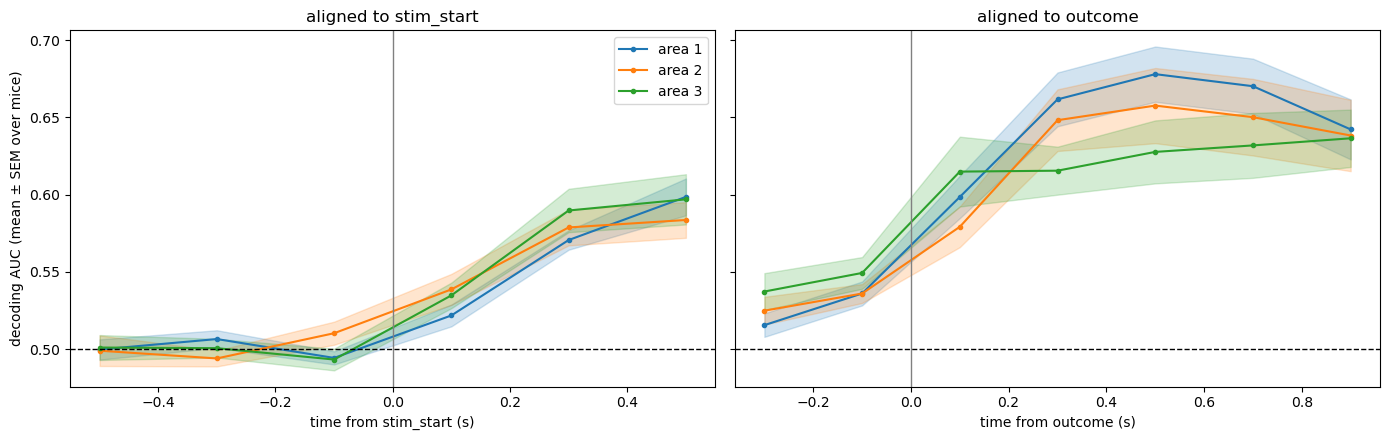

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ev in zip(axs, q.ALIGN):
    for a in AREAS:
        g = tim[(tim.event == ev) & (tim.area == a)].groupby("t").auc
        m_, se = g.mean(), g.sem()
        ax.plot(m_.index, m_, "-o", ms=3, color=AREA_COLORS[a], label=f"area {a}")
        ax.fill_between(m_.index, m_ - se, m_ + se, color=AREA_COLORS[a], alpha=0.2)
    ax.axhline(0.5, color="k", ls="--", lw=1); ax.axvline(0, color="0.5", lw=1)
    ax.set(xlabel=f"time from {ev} (s)", title=f"aligned to {ev}")
axs[0].set_ylabel("decoding AUC (mean ± SEM over mice)"); axs[0].legend()
fig.tight_layout()

## 3. Decoding per window and with all windows together

,W1 pre-stim (0.4 s),W2 post-stim (0.2 s),W3 post-outcome (1 s),all segments,"all segments, shuffled","all segments, full population"
area,,,,,,
1,0.503,0.515,0.687,0.683,0.497,0.822
2,0.504,0.539,0.680,0.687,0.496,0.790
3,0.497,0.535,0.656,0.668,0.495,0.732


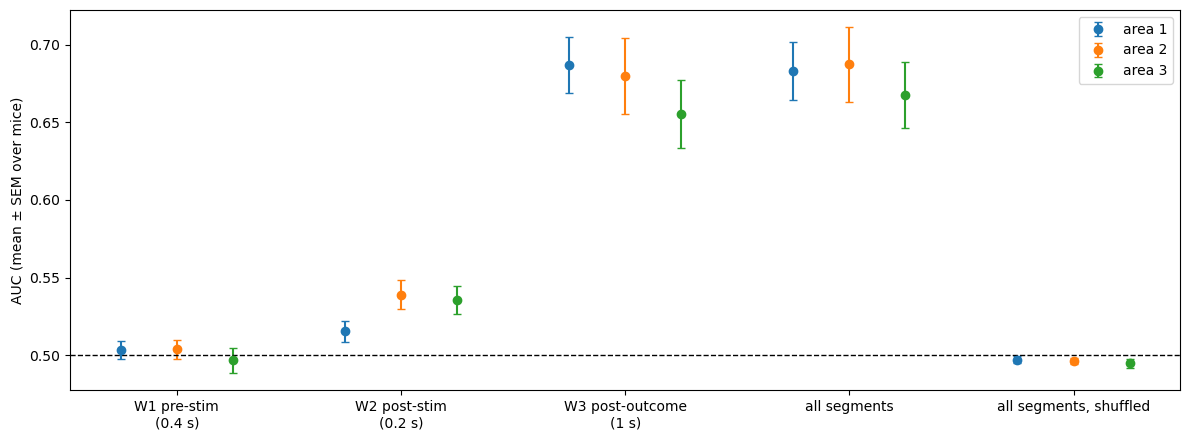

In [4]:
cols = WIN + ["all segments", "all segments, shuffled"]
fig, ax = plt.subplots(figsize=(12, 4.5))
for k, a in enumerate(AREAS):
    g = seg[seg.area == a]
    x = np.arange(len(cols)) + (k - 1) * 0.25
    ax.errorbar(x, g[cols].mean(), yerr=g[cols].sem(), fmt="o", color=AREA_COLORS[a], capsize=3, label=f"area {a}")
ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set(xticks=range(len(cols)), xticklabels=[c.replace(" (", "\n(") for c in cols], ylabel="AUC (mean ± SEM over mice)")
ax.legend()
fig.tight_layout()
seg.groupby("area")[cols + ["all segments, full population"]].mean().round(3)

## 4. Main comparison: all windows, 5 units per area

Friedman p = 8.0e-01


,mice where x > y,n mice,wilcoxon p
pair,,,
area 1 vs area 2,8,18,8.3e-01
area 1 vs area 3,10,18,5.5e-01
area 2 vs area 3,10,18,3.9e-01


,estimate,ci_low,ci_high,p (diff = 0)
area 1,0.683,0.650,0.721,NaN
area 2,0.687,0.645,0.736,NaN
area 3,0.668,0.631,0.712,NaN
area 1 − area 2,-0.004,-0.052,0.047,0.865
area 1 − area 3,0.016,-0.019,0.052,0.404
area 2 − area 3,0.020,-0.024,0.063,0.380


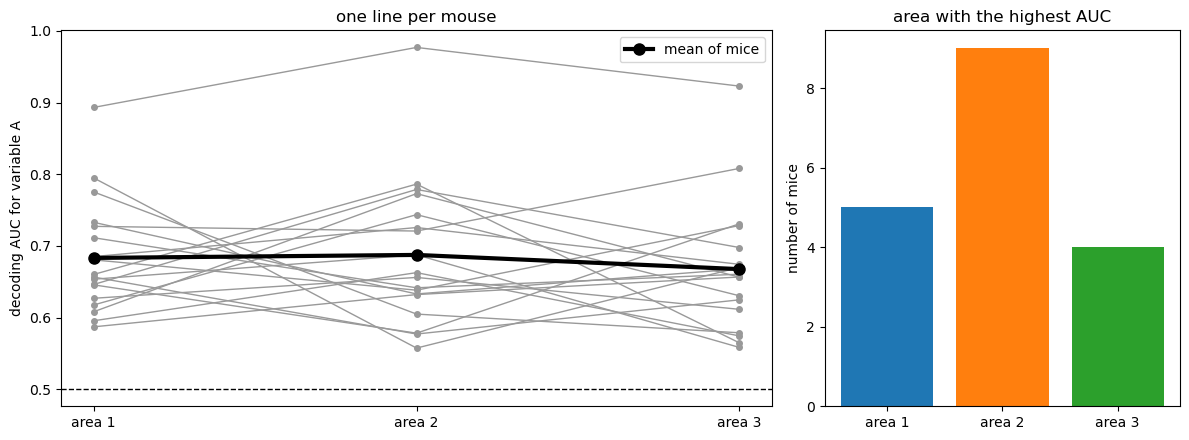

In [5]:
per_mouse, friedman, wilc = per_mouse_tests(seg, "all segments")
best = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
a1.axhline(0.5, color="k", ls="--", lw=1)
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="decoding AUC for variable A", title="one line per mouse")
a1.legend()
a2.bar([f"area {a}" for a in AREAS], best.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title="area with the highest AUC")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
display(wilc.style.format({"wilcoxon p": "{:.1e}"}))
t_main, _ = area_bootstrap(seg, "all segments")
t_main.round(3)

## 5. Robustness

In [6]:
peak = tim.groupby(["mouse", "area"]).auc.max().rename("peak time-bin AUC").reset_index()
variants = {"main: all windows, 5 units": seg[["mouse", "area", "all segments"]].rename(columns={"all segments": "v"}),
            "all windows, full population": seg[["mouse", "area", "all segments, full population"]].rename(columns={"all segments, full population": "v"}),
            "post-outcome window only (W3), 5 units": seg[["mouse", "area", WIN[2]]].rename(columns={WIN[2]: "v"}),
            "best 200-ms bin, 5 units": peak.rename(columns={"peak time-bin AUC": "v"})}
rows = {}
for lab, d in variants.items():
    pm, fr, w = per_mouse_tests(d, "v")
    top = pm.mean().idxmax()
    rows[lab] = {**{f"area {a}": pm[a].mean() for a in AREAS}, "highest (mean of mice)": f"area {top}",
                 "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index()), "Friedman p": fr.pvalue,
                 **{f"Wilcoxon {x} vs {y}": w.loc[f"area {x} vs area {y}", "wilcoxon p"] for x, y in [(1, 2), (1, 3), (2, 3)]}}
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,highest (mean of mice),highest in n mice,Friedman p,Wilcoxon 1 vs 2,Wilcoxon 1 vs 3,Wilcoxon 2 vs 3
"main: all windows, 5 units",0.683157,0.687356,0.667545,area 2,"{1: 5, 2: 9, 3: 4}",0.800737,0.831726,0.550873,0.392738
"all windows, full population",0.82207,0.790233,0.732327,area 1,"{1: 7, 2: 8, 3: 3}",0.091732,0.522614,0.00193,0.181465
"post-outcome window only (W3), 5 units",0.686956,0.679665,0.655662,area 1,"{1: 6, 2: 9, 3: 3}",0.67781,1.0,0.154045,0.468292
"best 200-ms bin, 5 units",0.711803,0.69248,0.689931,area 1,"{1: 4, 2: 8, 3: 6}",0.945959,0.701881,0.417114,0.898575


### Larger equal-size populations

Five units is a small population, so a real difference could be missed. Here the comparison is repeated with 10 and 15 units per area, in the mice that have that many units in all three areas.

In [7]:
big = pd.read_csv(RESULTS_DIR / "q11_larger_populations.csv")     # computed with q.decode_area, see the Q11 log
for N, g in big.groupby("N"):
    t = g.pivot(index="mouse", columns="area", values="auc")
    print(f"{N} units per area, {len(t)} mice: mean AUC {t.mean().round(3).to_dict()}, highest per mouse "
          f"{t.idxmax(axis=1).value_counts().sort_index().to_dict()}, Friedman p = {sps.friedmanchisquare(*[t[a] for a in AREAS]).pvalue:.2f}")

10 units per area, 14 mice: mean AUC {1: 0.747, 2: 0.722, 3: 0.707}, highest per mouse {1: 4, 2: 6, 3: 4}, Friedman p = 0.53
15 units per area, 7 mice: mean AUC {1: 0.782, 2: 0.742, 3: 0.727}, highest per mouse {1: 3, 2: 2, 3: 2}, Friedman p = 0.56


## 6. Answer for the questionnaire

**Not enough data / no differences.**
- A is decodable from every area, at a similar level, and only after the outcome (consistent with A being trial outcome).
- With equal-size populations (5, 10 or 15 units), no area carries more information than the others.
- Area 1 comes out ahead only with full populations, because it has the most recorded units (36 per mouse on average, against 18 in area 3). That reflects how many neurons were sampled, not how much an area's population encodes.

In [8]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
rows_q = [(f"{r.Mean:.3f}", f"[{r['CI low']:.3f}, {r['CI high']:.3f}]", "ROC AUC") for _, r in answer.iterrows()]
answer.to_csv(RESULTS_DIR / "q11_answer.csv")
m = t_main.estimate
full = seg.groupby("area")["all segments, full population"].mean()
expl = (
    f"I decoded variable A trial by trial from each area's spikes with cross-validated logistic regression (5 folds), "
    f"scored by ROC AUC (chance 0.5; insensitive to A being unbalanced). Inter-trial intervals were excluded. Because "
    f"the informative segment is not known, the main decoder used spike counts in three fixed-length windows together: "
    f"0.4 s before the stimulus, 0.2 s after the stimulus and 1 s after the outcome. Fixed lengths were needed because "
    f"trials with A = 0 have a 1-s longer post-outcome period, so segment-averaged rates would differ for that reason "
    f"alone. To compare areas fairly each decoder used the same number of units (5, the size of the smallest area; 20 "
    f"random draws), and values are means over mice with a bootstrap CI. A was decodable only after the outcome and "
    f"equally well in all areas (AUC {m['area 1']:.3f}, {m['area 2']:.3f}, {m['area 3']:.3f}; shuffled labels 0.50; "
    f"Friedman p = {friedman.pvalue:.2f}), and the same held with 10 and 15 units per area, for the post-outcome window "
    f"alone and for the best 200-ms bin. Only full populations favoured area 1 (AUC {full[1]:.2f} vs {full[2]:.2f} and "
    f"{full[3]:.2f}), which reflects its larger number of recorded units rather than more information."
)
print(len(expl.split()), "words"); print(expl)
record_answer(11, choice=3, rows=rows_q, explanation=expl)  # 3 = not enough data / no differences
record_meta(11, confidence=5, consensus=3)
print(fill_pdf())

193 words
I decoded variable A trial by trial from each area's spikes with cross-validated logistic regression (5 folds), scored by ROC AUC (chance 0.5; insensitive to A being unbalanced). Inter-trial intervals were excluded. Because the informative segment is not known, the main decoder used spike counts in three fixed-length windows together: 0.4 s before the stimulus, 0.2 s after the stimulus and 1 s after the outcome. Fixed lengths were needed because trials with A = 0 have a 1-s longer post-outcome period, so segment-averaged rates would differ for that reason alone. To compare areas fairly each decoder used the same number of units (5, the size of the smallest area; 20 random draws), and values are means over mice with a bootstrap CI. A was decodable only after the outcome and equally well in all areas (AUC 0.683, 0.687, 0.668; shuffled labels 0.50; Friedman p = 0.80), and the same held with 10 and 15 units per area, for the post-outcome window alone and for the best 200-ms bin. 

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
